## Workflow 5: Human-in-the-Loop (HITL)

"Human-in-the-Loop is a workflow pattern in which an AI system pauses execution and requests human input, approval, or feedback before proceeding with a particular action."

Simple language mein:

AI apna kaam kar raha hai. Lekin kisi important action ko execute karne se pehle woh rukega aur human se permission lega.

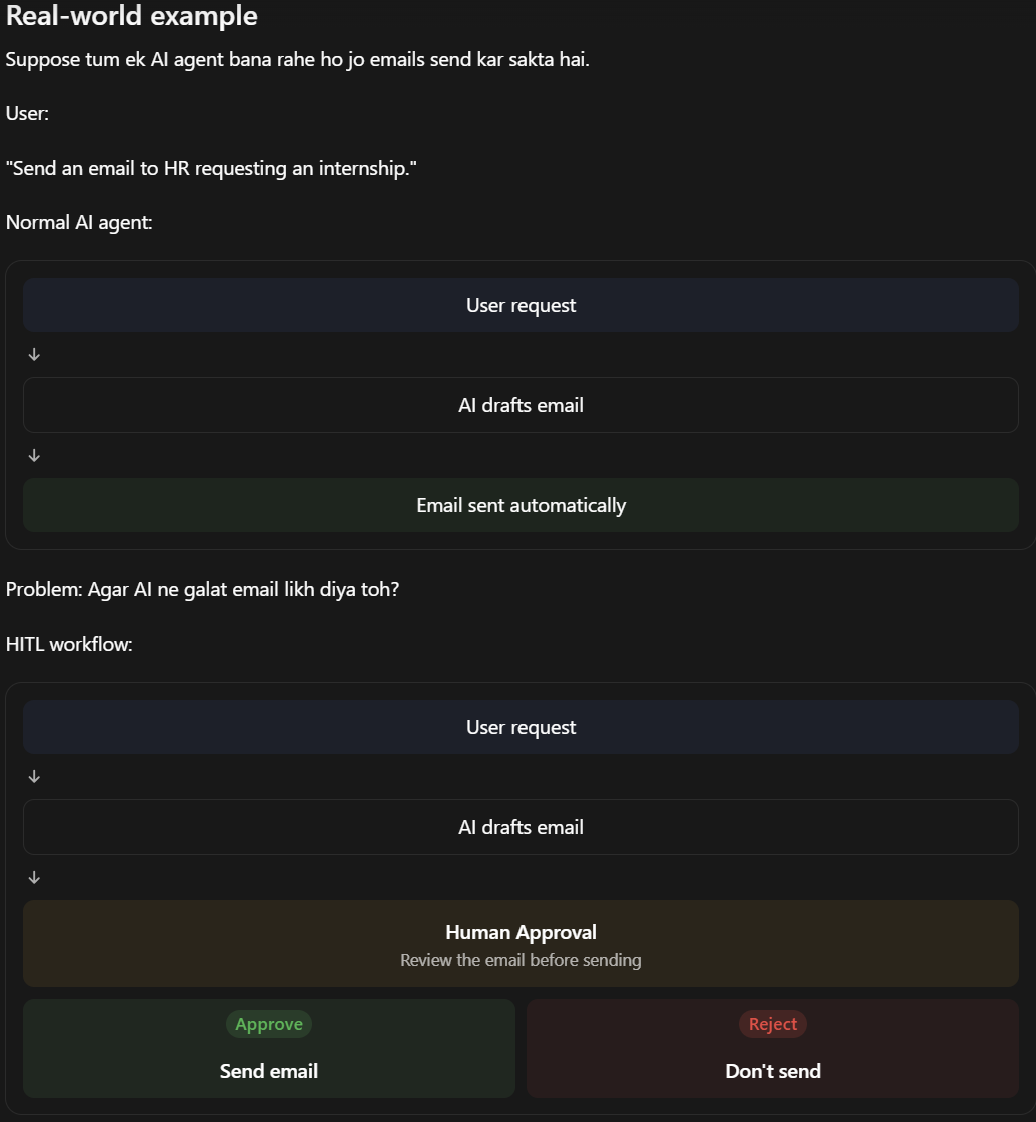

# . LangGraph mein HITL kaise implement hota hai?
Important API
 interrupt()

LangGraph ka interrupt() function graph execution ko pause kar deta hai.

Human decision dene ke baad Command(resume=...) se execution resume kar sakte hain.

Iske liye humein ek checkpointer bhi chahiye, jo paused graph ki state ko save rakhe.

Hum use karenge:
# from langgraph.types import interrupt, Command
# from langgraph.checkpoint.memory import InMemorySaver

Practical implementation: Email approval workflow


Step 1 — Define State

In [24]:
from typing import TypedDict

class GraphState(TypedDict):
    recipient: str
    email_content: str
    approved: bool
    result: str

# State mein:
# - recipient: Email kisko bhejna hai.
# - email_content: Email ka content.
# - approved: Human ne approve kiya ya nahi.
# - result: Final execution status.

Step 2 — Create approval node
Ye sabse important node hai.

In [25]:
from langgraph.types import interrupt

def approval_node(state: GraphState):

    decision = interrupt({
        "message": "Please review this email before sending.",
        "recipient": state["recipient"],
        "email_content": state["email_content"]
    })

    return {
        "approved": decision == "approve"
    }



#     Samjho:
# 1. Node interrupt() call karta hai.
# 2. Graph execution pause ho jata hai.
# 3. Human ko email details dikhayi jaati hain.
# 4. Human approve ya reject decide karta hai.
# 5. Graph resume hone par decision node ko milta hai.

Step 3 — Create execution nodes


In [26]:
# Approved node
def send_email_node(state: GraphState):

    # Demo: No actual email is sent

    return {
        "result": (
            f"Email successfully simulated for "
            f"{state['recipient']}"
        )
    }


# Rejected node:
def reject_node(state: GraphState):

    return {
        "result": "Email sending was rejected by the human."
    }


Step 4 — Create conditional routing

In [27]:
def route_after_approval(state: GraphState):

    if state["approved"]:
        return "send"

    return "reject"


    #Yahan human ke decision ke basis par next node select hoga.

Step 5 — Create StateGraph

In [28]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

builder = StateGraph(GraphState)

# Add nodes
builder.add_node("approval", approval_node)
builder.add_node("send", send_email_node)
builder.add_node("reject", reject_node)

# Starting edge
builder.add_edge(START, "approval")

# Conditional routing
builder.add_conditional_edges(
    "approval",
    route_after_approval,
    {
        "send": "send",
        "reject": "reject"
    }
)

# End edges
builder.add_edge("send", END)
builder.add_edge("reject", END)

# Checkpointer
memory = InMemorySaver()

# Compile
graph = builder.compile(checkpointer=memory)



# Why InMemorySaver?

# Jab graph pause hota hai, humein uski previous state preserve karni hoti hai.

# Checkpointer execution state ko save karta hai, taaki human ke response ke baad graph wahi se resume ho sake.

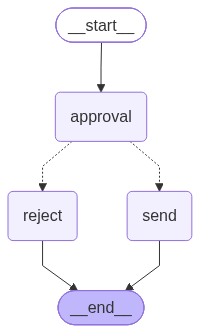

In [29]:
from IPython.display import display, Markdown, Image

display(Image(graph.get_graph().draw_mermaid_png()))

 Invoke the graph

In [30]:
config = {
    "configurable": {
        "thread_id": "email_approval_1"
    }
}

result = graph.invoke(
    {
        "recipient": "hr@example.com",
        "email_content": (
            "Hello, I am interested in applying "
            "for a software engineering internship."
        ),
        "approved": False,
        "result": ""
    },
    config=config
)

print(result)

{'recipient': 'hr@example.com', 'email_content': 'Hello, I am interested in applying for a software engineering internship.', 'approved': False, 'result': '', '__interrupt__': [Interrupt(value={'message': 'Please review this email before sending.', 'recipient': 'hr@example.com', 'email_content': 'Hello, I am interested in applying for a software engineering internship.'}, id='695b8ce2adfed171a8d70ed652c0a68d', response_schema=None)]}


Step 7 — Human approval
Ab human decision dega.

In [31]:
# #Approve 
# from langgraph.types import Command

# result = graph.invoke(
#     Command(resume="approve"),
#     config=config
# )

# print(result["result"])



#Reject:

result = graph.invoke(
    Command(resume="reject"),
    config=config
)

print(result["result"])

Email sending was rejected by the human.


Three concepts you must remember
Concept	Meaning
interrupt()	Pauses graph execution and requests human input
InMemorySaver()	Saves graph state in memory
Command(resume=...)	Resumes paused graph with human's decision

Ek important technical detail: interrupt() ko use karte waqt node resume hone par beginning se dobara execute ho sakta hai. Isliye interrupt se pehle koi irreversible side effect (jaise actual email send karna) perform mat karna.

Also, InMemorySaver learning/testing ke liye hai. Production mein persistent checkpointer use karna chahiye.

7. Interview mein kaise explain karoge?
"Human-in-the-Loop in LangGraph allows us to pause an agent's execution using the interrupt mechanism. The graph saves its state through a checkpointer. A human can review the pending action and provide approval or rejection. We then resume execution using Command with the human's decision."

## Memory



LangGraph mein memory ko broadly do parts mein samajh sakte hain:
1. Short-term memory (Thread-level memory)
Ye ek particular conversation ki memory hoti hai.

Example:
- User: My name is Rahul.
- User: What is my name?
- AI: Your name is Rahul.
AI ko previous messages yaad rehne chahiye.

Iske liye LangGraph mein Checkpointer use hota hai.
from langgraph.checkpoint.memory import InMemorySavermemory = InMemorySaver()graph = builder.compile(    checkpointer=memory)



Invocation:
config = {    "configurable": {        "thread_id": "user_1"    }}result = graph.invoke(    {"messages": [("user", "My name is Rahul")]},    config=config)



Next message:
result = graph.invoke(    {"messages": [("user", "What is my name?")]},    config=config)



Same thread_id hone ki wajah se graph previous conversation state access kar sakta hai.
2. Long-term memory (Cross-thread memory)
Suppose user ne ek conversation mein bataya:

"My favourite programming language is Python."

Ab user ek completely new conversation start karta hai, different thread_id ke saath.

Kya AI ko Python preference yaad rehni chahiye?

Agar haan, toh humein Long-term memory chahiye.

LangGraph mein iske liye Store use kar sakte hain.
from langgraph.store.memory import InMemoryStorestore = InMemoryStore()



Store mein information namespaces aur keys ke through save/retrieve hoti hai.
3. InMemorySaver vs InMemoryStore
InMemorySaver
Short-term / Checkpointing
- Conversation state save karta hai.
- Same thread ko resume kar sakte hain.
- Previous messages aur workflow progress preserve kar sakte hain.

InMemoryStore
Long-term / Cross-thread
- User-specific information store kar sakta hai.
- Different threads mein information access kar sakte hain.
- Persistent memory-like data manage kar sakte hain.

4. Important: InMemory ka matlab?
Dono InMemorySaver aur InMemoryStore memory mein data rakhte hain.

Application/process restart hone par in-memory data generally lost ho jata hai.

Production mein persistent database-backed checkpointer aur store use karte hain.

Examples:
- PostgreSQL
- Redis
- Other supported persistent storage backends
5. Interview-ready answer
"LangGraph supports short-term and long-term memory. Short-term memory is managed using checkpointers, which preserve conversation state within a thread. Long-term memory is managed using stores, which allow information to be shared across different threads. InMemorySaver and InMemoryStore are in-memory implementations used mainly for development and testing."